# A simple PyTorch classifier for MNIST

Logistic regression computes 10 scores straight from the 784 pixels. A **neural network** puts a
**hidden layer** in between: it first computes many intermediate features (strokes, loops…), then the scores.

We build both in PyTorch with the same training loop and compare them.

Intuition first: [3Blue1Brown — But what is a neural network?](https://www.youtube.com/watch?v=aircAruvnKk) (19 min).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.datasets import fetch_openml
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

device: cpu


## 1. Data → tensors
The same MNIST split as before (80% train, 20% validation). PyTorch works on **tensors**; a `DataLoader` serves them in small shuffled batches.

In [2]:
def load_mnist(n=42000, val_fraction=0.2, seed=42):
    X, y = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True, parser="liac-arff")
    X, y = X[:n].astype(np.float32) / 255.0, y[:n].astype(np.int64)
    idx = np.random.default_rng(seed).permutation(n)
    val, train = idx[:int(n * val_fraction)], idx[int(n * val_fraction):]
    return [torch.from_numpy(a) for a in (X[train], y[train], X[val], y[val])]


X_train, y_train, X_val, y_val = load_mnist()
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=128, shuffle=True)
print("train:", tuple(X_train.shape), "validation:", tuple(X_val.shape))

train: (33600, 784) validation: (8400, 784)


## 2. Two models
- **Logistic regression** = one linear layer: 784 pixels → 10 scores.
- **Neural network (MLP)** = linear → **ReLU** → linear. ReLU (`max(0, x)`) is what makes it non-linear; without it two linear layers would collapse into one.

In [3]:
def logistic_regression():
    return nn.Linear(784, 10)


def mlp(hidden=128):
    return nn.Sequential(nn.Linear(784, hidden), nn.ReLU(), nn.Linear(hidden, 10))


for name, model in [("logistic regression", logistic_regression()), ("MLP", mlp())]:
    print(f"{name}: {sum(p.numel() for p in model.parameters()):,} parameters")

logistic regression: 7,850 parameters
MLP: 101,770 parameters


## 3. The training loop — five steps per batch
1. **forward** — compute the scores; 2. **loss** — how wrong they are (cross-entropy = softmax + log loss); 3. **backward** — gradients of the loss; 4. **step** — the optimiser moves the weights; 5. **zero_grad** — clear gradients for the next batch.

In [4]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    total = 0.0
    for X, y in loader:
        X, y = X.to(DEVICE), y.to(DEVICE)
        scores = model(X)            # 1. forward
        loss = loss_fn(scores, y)    # 2. loss
        optimizer.zero_grad()        # 5. clear old gradients
        loss.backward()              # 3. backward
        optimizer.step()             # 4. update weights
        total += loss.item() * len(X)
    return total / len(loader.dataset)


@torch.no_grad()
def predict(model, X):
    model.eval()
    return model(X.to(DEVICE)).argmax(dim=1).cpu()


def accuracy(model, X, y):
    return (predict(model, X) == y).float().mean().item()

## 4. Train both models
`Adam` is a popular optimiser; one **epoch** = one pass over the training data.

In [5]:
def fit(model, epochs=5, lr=1e-3):
    model = model.to(DEVICE)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    for epoch in range(1, epochs + 1):
        loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
        acc = accuracy(model, X_val, y_val)
        history.append((loss, acc))
        print(f"epoch {epoch}: train loss {loss:.3f}  validation accuracy {acc:.4f}")
    return model, history


print("logistic regression"); logreg, hist_lr = fit(logistic_regression())
print("MLP");                 net, hist_mlp = fit(mlp())

logistic regression


epoch 1: train loss 0.857  validation accuracy 0.8762
epoch 2: train loss 0.429  validation accuracy 0.8956


epoch 3: train loss 0.362  validation accuracy 0.9018
epoch 4: train loss 0.332  validation accuracy 0.9088


epoch 5: train loss 0.313  validation accuracy 0.9113
MLP
epoch 1: train loss 0.541  validation accuracy 0.9199


epoch 2: train loss 0.238  validation accuracy 0.9379
epoch 3: train loss 0.182  validation accuracy 0.9455


epoch 4: train loss 0.145  validation accuracy 0.9535
epoch 5: train loss 0.122  validation accuracy 0.9552


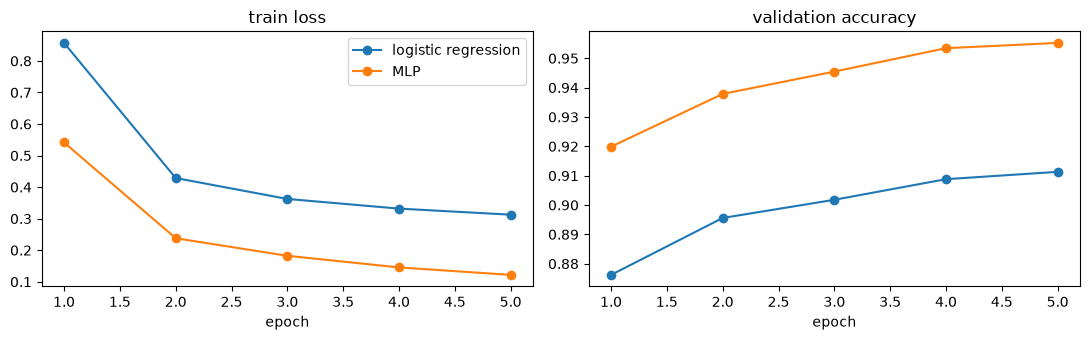

In [6]:
def plot_history(histories):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
    for name, h in histories.items():
        epochs = range(1, len(h) + 1)
        ax1.plot(epochs, [l for l, _ in h], marker="o", label=name)
        ax2.plot(epochs, [a for _, a in h], marker="o", label=name)
    ax1.set(title="train loss", xlabel="epoch")
    ax2.set(title="validation accuracy", xlabel="epoch")
    ax1.legend()
    plt.tight_layout()
    plt.show()


plot_history({"logistic regression": hist_lr, "MLP": hist_mlp})

## 5. What does the network still get wrong?

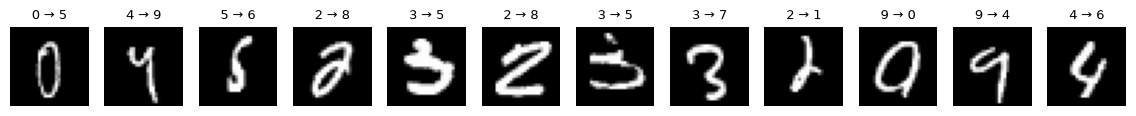

In [7]:
def show_mistakes(model, X, y, n=12):
    pred = predict(model, X)
    wrong = torch.nonzero(pred != y).flatten()[:n]
    fig, axes = plt.subplots(1, n, figsize=(n * 1.2, 1.6))
    for ax, i in zip(axes, wrong):
        ax.imshow(X[i].reshape(28, 28), cmap="gray")
        ax.set_title(f"{y[i].item()} → {pred[i].item()}", fontsize=9)
        ax.axis("off")
    plt.show()


show_mistakes(net, X_val, y_val)

## Takeaways

- In PyTorch, logistic regression is just **one linear layer** trained with cross-entropy.
- One hidden layer + ReLU lets the model combine pixels into features — accuracy jumps.
- The **training loop** (forward → loss → backward → step → zero_grad) is the same for every network, from this one to large CNNs.
- **Try:** more hidden units (`mlp(256)`), more epochs, a second hidden layer — and watch validation accuracy, not only training loss.